# MetricSuite 6 -- The bootstrap

The bootstrap estimates the uncertainty of **any** statistic by recomputing it on
resampled data. In the suite it is a way to build a confidence interval
(`ci_method="bootstrap"`), and a test built on the same draws
(`suite.stat.bootstrap`):

- **Part 1** -- the idea, by hand;
- **Part 2** -- bootstrap intervals in `suite.estimate`;
- **Part 3** -- the bootstrap test, and how it agrees with the interval;
- **Part 4** -- draws made upstream: a spike-resampling pipeline feeding the suite;
- **Part 5** -- limits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mindmap.metric import MetricSuite
from mindmap.core.stats import bootstrap_draws, percentile_interval, bootstrap_pvalue

COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948"}

## 🎲 - Part 1: The idea

We have one sample -- say 25 paired differences. The statistic we report (here the
mean) would come out differently on another sample of 25 patients. How differently?
We can't draw new patients, but we can **resample the ones we have**: draw 25 with
replacement (some twice, some not at all), recompute the mean, and repeat thousands
of times. The spread of these *bootstrap draws* mimics the spread across samples.
The **percentile interval** is the middle 95% of the draws.

(0.383, 1.446)

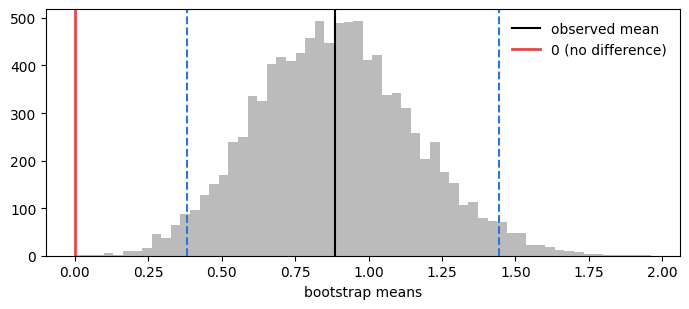

In [2]:
rng = np.random.default_rng(0)
d = rng.gamma(2.0, 1.0, size=25) - 1.0        # 25 skewed paired differences

draws = bootstrap_draws(d, estimator="mean", n_boot=10_000, seed=1)
low, high = percentile_interval(draws, alpha=0.05)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(draws, bins=60, color="#bbbbbb")
ax.axvline(d.mean(), color="black", label="observed mean")
for v in (low, high):
    ax.axvline(v, color="#2a78d6", linestyle="--")
ax.axvline(0, color="#e34948", linewidth=2, label="0 (no difference)")
ax.set_xlabel("bootstrap means")
ax.legend(frameon=False)
fig.tight_layout()
(round(low, 3), round(high, 3))

The same draws give a p-value: the share of draws on the far side of 0 (doubled for
two-sided), with a +1 so it is never exactly 0. It is below 0.05 exactly when the
95% interval excludes 0 -- the test and the interval can't disagree.

In [3]:
bootstrap_pvalue(draws, null=0.0)

0.00019998000199980003

Why bother, when the t interval exists? Because the bootstrap works the same way
for **any** statistic -- a median, a rank-biserial r, a Cohen's dz, a correlation
computed upstream -- including those with no textbook interval.

## 📐 - Part 2: Bootstrap intervals in `suite.estimate`

Every estimator in `suite.estimate` takes `ci_method="bootstrap"`:

- `n_boot` resamples (default 10,000);
- `seed` -- drawn at random when omitted, and **stored on the result** either way,
  so every interval can be reproduced.

The resampled units are the ones the estimate reads after collapsing: whole
`pairing_col` units for a paired estimate (a patient keeps both methods' values
together), `unit_col` values, else rows.

In [4]:
TRUE_ERROR = {"wCSET": 13.0, "CSET": 14.5, "dSPM": 19.0}
rng = np.random.default_rng(6)
suite = MetricSuite(name="Bootstrap")
for p in range(30):
    difficulty = rng.normal(0, 5)
    for method, mu in TRUE_ERROR.items():
        suite.register("loc_error_mm", max(mu + difficulty + rng.gamma(2.0, 1.5), 0.5),
                       method=method, patient=f"P{p:02d}")

comparisons = suite.stat.build_comparisons("wCSET", ["CSET", "dSPM"])
kws = dict(group_by="method", comparisons=comparisons, pairing_col="patient")

For an estimator that has an analytic interval, the two agree closely:

In [5]:
analytic = suite.estimate.hodges_lehmann("loc_error_mm", **kws)
boot = suite.estimate.hodges_lehmann("loc_error_mm", **kws, ci_method="bootstrap", seed=0)
pd.concat({"analytic (signed-rank)": analytic.vs("wCSET", False)[["estimate", "ci_low", "ci_high"]],
           "bootstrap": boot.vs("wCSET", False)[["estimate", "ci_low", "ci_high"]]}, axis=1).round(3)

analytic (signed-rank)                bootstrap               
                     estimate ci_low ci_high  estimate ci_low ci_high
method                                                               
CSET                    1.218  0.174   2.466     1.218  0.179   2.393
dSPM                    5.242  4.403   5.843     5.242  4.443   5.839

For a standardized effect size, the bootstrap is the only interval available:

In [6]:
dz = suite.estimate.cohens_dz("loc_error_mm", **kws, ci_method="bootstrap", seed=0)
r = suite.estimate.rank_biserial("loc_error_mm", **kws, ci_method="bootstrap", seed=0)
pd.concat({"cohens_dz": dz.vs("wCSET", False), "rank_biserial": r.vs("wCSET", False)}, axis=1).round(3)

cohens_dz                                                rank_biserial  \
        estimate ci_low ci_high n_reference n_competitor n_boot      estimate   
method                                                                          
CSET       0.427  0.108   0.772          30           30  10000         0.484   
dSPM       2.246  1.607   3.753          30           30  10000         0.987   

                                                       
       ci_low ci_high n_reference n_competitor n_boot  
method                                                 
CSET    0.101   0.798          30           30  10000  
dSPM    0.935   1.000          30           30  10000

The result records how it was built:

In [7]:
dz.ci_method, dz.bootstrap, dz.table["ci_method"].iloc[0]

('bootstrap',
 {'n_boot': 10000, 'seed': 0, 'replicates': None, 'replicate_col': None},
 'bootstrap_percentile')

Rerunning with the stored seed gives exactly the same interval:

In [8]:
again = suite.estimate.cohens_dz("loc_error_mm", **kws, ci_method="bootstrap", seed=dz.bootstrap["seed"])
again.table[["ci_low", "ci_high"]].equals(dz.table[["ci_low", "ci_high"]])

True

## 🧪 - Part 3: The bootstrap test

`suite.stat.bootstrap` tests any difference estimator (`estimator=`, default
`"mean_diff"`) with the bootstrap p-value. It returns an ordinary `PairwiseResult`:
corrections, `vs()`, plots, saving and `verify` all work as for the other tests.

In [9]:
bt = suite.stat.bootstrap("loc_error_mm", **kws, estimator="hodges_lehmann", seed=0, correction="holm")
bt

PairwiseResult(metric='loc_error_mm', test='bootstrap', estimator='hodges_lehmann', n_boot=10000, correction='holm', alpha=0.05, n_comparisons=2)
  wCSET vs CSET: p=0.017*, hodges_lehmann=-1.22 [-2.39, -0.179], n=30
  wCSET vs dSPM: p=0.0004*, hodges_lehmann=-5.24 [-5.84, -4.44], n=30

In [10]:
bt.vs("wCSET", higher_is_better=False)

,p_value,p_corrected,significant,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high,offset,alternative,n_pairs,n_boot
method,,,,,,,,,,
CSET,0.016998,0.016998,True,1.218083,0.179247,2.392567,0.0,two-sided,30,10000
dSPM,0.000200,0.000400,True,5.242371,4.442754,5.838539,0.0,two-sided,30,10000


The result also holds the estimator's percentile interval, from **the very same
draws** as the p-value: the interval excludes 0 exactly when the test is significant
(before the multiple-comparison correction). `estimate.from_result` on a bootstrap
test reuses its seed, so it gives the same interval as an `EstimateResult`.

In [11]:
bt.vs("wCSET", False)[["p_value", "p_corrected", "hodges_lehmann", "hodges_lehmann_ci_low", "hodges_lehmann_ci_high"]]

,p_value,p_corrected,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high
method,,,,,
CSET,0.016998,0.016998,1.218083,0.179247,2.392567
dSPM,0.000200,0.000400,5.242371,4.442754,5.838539


### Offsets: non-inferiority with any estimator

`offset` and `alternative` work as in the other tests, in the estimator's units --
e.g. "is wCSET's HL loss vs CSET smaller than 2 mm?":

In [12]:
ni = suite.stat.bootstrap("loc_error_mm", "method", [("wCSET", "CSET")], pairing_col="patient",
                          estimator="hodges_lehmann", offset=2.0, alternative="less", seed=0)
ni.vs("wCSET", higher_is_better=False)[["p_value", "hodges_lehmann", "offset", "alternative"]]

,p_value,hodges_lehmann,offset,alternative
method,,,,
CSET,0.0001,1.218083,-2.0,greater


### `n_boot` limits the smallest p-value

With B draws, the smallest two-sided p is 2 / (B + 1). With Holm across m
comparisons, the smallest p must clear alpha / m -- so B must be well above
2m / alpha. With only 200 draws, the smallest p is 2 / 201 ≈ 0.0100: even the
overwhelming `dSPM` effect sits on that floor, and in a family of 6 comparisons
(Holm threshold 0.05 / 6 ≈ 0.0083) it could never be declared significant:

In [13]:
tiny = suite.stat.bootstrap("loc_error_mm", **kws, n_boot=200, seed=0)
tiny.table[["group_a", "group_b", "n_boot", "p_value"]].assign(floor=2 / 201, smallest_holm_threshold_m6=0.05 / 6)

,group_a,group_b,n_boot,p_value,floor,smallest_holm_threshold_m6
0,wCSET,CSET,200,0.01990,0.00995,0.008333
1,wCSET,dSPM,200,0.00995,0.00995,0.008333


The default 10,000 draws reach p ≈ 2e-4, enough for a few dozen comparisons.

### Plots

The stat plots accept a bootstrap result. `paired_differences` draws the
bootstrapped estimate with its bootstrap interval (same seed, same draws):

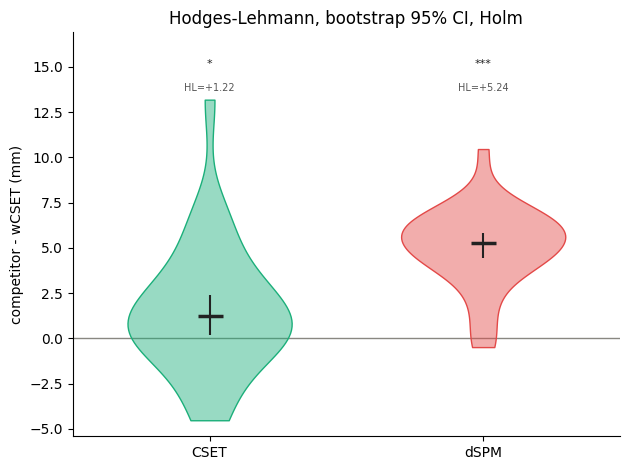

In [14]:
fig, ax = suite.plot.paired_differences(bt, higher_is_better=False, palette=COLORS,
                                        annotate=("stars", "hodges_lehmann"),
                                        ylabel="competitor - wCSET (mm)",
                                        title="Hodges-Lehmann, bootstrap 95% CI, Holm")
fig.tight_layout()

## 🔧 - Part 4: Draws made upstream

### When the suite can't resample

Sometimes the units to resample live **before** the suite. Example: per subject,
a virtual iEEG is built from the average of 60 spikes, then correlated with the real
iEEG (`rho`). The uncertainty comes from *which spikes* were averaged. The suite
only sees the final `rho` -- one number per subject and method -- so it has nothing
to resample.

The pipeline does the resampling: for each draw, resample the spikes, re-average,
recompute `rho` **for every method on the same resample** (a paired bootstrap).
The suite then reads the draws:

- the observed values (all spikes) under the main metric, `rho`;
- one value per draw under a **separate** metric, `rho_boot`, numbered by a column,
  `boot`. Keeping draws in their own metric means no other analysis of `rho`
  accidentally mixes them in.

### A toy pipeline

In [15]:
N_SPIKES, N_TIMES, B = 60, 80, 1000
template = np.sin(np.linspace(0, 3 * np.pi, N_TIMES)) * np.hanning(N_TIMES)
NOISE = {"wCSET": 2.0, "CSET": 3.0, "dSPM": 4.5}          # how noisy each method's estimate is
SUBJECTS = ["S1", "S2", "S3"]


def rho_from(spike_estimates, real):
    return float(np.corrcoef(spike_estimates.mean(axis=0), real)[0, 1])


rng = np.random.default_rng(1)
pipeline = MetricSuite(name="Virtual iEEG")
for subject in SUBJECTS:
    real = template + rng.normal(0, 0.15, N_TIMES)                       # the real iEEG
    shared = rng.normal(0, 1.0, (N_SPIKES, N_TIMES))                      # spike-to-spike variability
    estimates = {m: template + shared + rng.normal(0, s, (N_SPIKES, N_TIMES)) for m, s in NOISE.items()}

    resamples = rng.integers(0, N_SPIKES, size=(B, N_SPIKES))             # one resample per draw, shared
    for method, est in estimates.items():
        pipeline.register("rho", rho_from(est, real), method=method, subject=subject)
        draws = [rho_from(est[idx], real) for idx in resamples]
        pipeline.register("rho_boot", np.array(draws), method=method, subject=subject, boot=np.arange(B))

pipeline.describe()

,Metric,Coord,Kind,N unique,Detail
0,rho,method,categorical,3,"CSET, dSPM, wCSET"
1,rho,subject,categorical,3,"S1, S2, S3"
2,rho_boot,method,categorical,3,"CSET, dSPM, wCSET"
3,rho_boot,subject,categorical,3,"S1, S2, S3"
4,rho_boot,boot,numerical,1000,"[0, 999]"


### Testing per subject, Holm across competitors

Point `suite.stat.bootstrap` at the draws with `replicates` (the metric) and
`replicate_col` (the column numbering them). Here, one family per subject:
`filters` keeps one subject, and Holm corrects across the two competitors.

In [16]:
results = {}
for subject in SUBJECTS:
    results[subject] = pipeline.stat.bootstrap(
        "rho", "method", pipeline.stat.build_comparisons("wCSET", ["CSET", "dSPM"]),
        pairing_col="subject", replicates="rho_boot", replicate_col="boot",
        filters={"subject": subject}, correction="holm",
    )
results["S1"]

PairwiseResult(metric='rho', test='bootstrap', estimator='mean_diff', replicates='rho_boot', correction='holm', alpha=0.05, n_comparisons=2)
  wCSET vs CSET: p=0.1798, mean_diff=0.0678 [-0.0328, 0.218], n=1
  wCSET vs dSPM: p=0.04795*, mean_diff=0.0759 [0.0157, 0.236], n=1

In [17]:
columns = ["mean_diff", "mean_diff_ci_low", "mean_diff_ci_high", "p_value", "p_corrected", "n_boot"]
pd.concat({s: r.vs("wCSET")[columns] for s, r in results.items()}).round(4)

mean_diff  mean_diff_ci_low  mean_diff_ci_high  p_value  \
   method                                                            
S1 CSET       0.0678           -0.0328             0.2177   0.1798   
   dSPM       0.0759            0.0157             0.2357   0.0240   
S2 CSET       0.2192            0.1052             0.3497   0.0020   
   dSPM       0.2245            0.1239             0.3832   0.0020   
S3 CSET       0.1531            0.0384             0.2821   0.0140   
   dSPM       0.2078            0.0911             0.3650   0.0020   

           p_corrected  n_boot  
   method                       
S1 CSET         0.1798    1000  
   dSPM         0.0480    1000  
S2 CSET         0.0040    1000  
   dSPM         0.0040    1000  
S3 CSET         0.0140    1000  
   dSPM         0.0040    1000

The point estimate (`mean_diff` = Δρ) comes from the observed `rho`; the interval
and p-value from the 1,000 draws. `wCSET` beats `dSPM` in every subject; its edge
over `CSET` is clear in some subjects and within the spike-sampling noise in
others -- exactly what a per-subject bootstrap is meant to show. `verify` covers both metrics: register another
draw and the results no longer match the data.

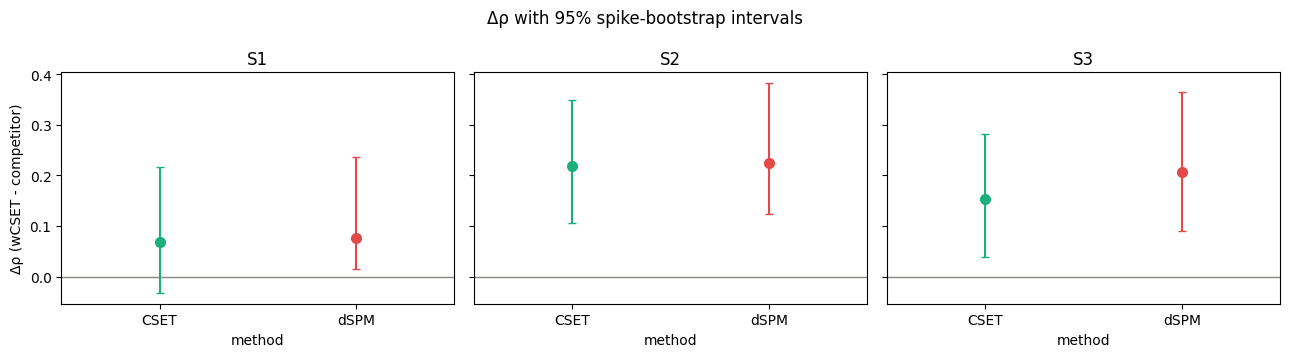

In [18]:
fig, axes = plt.subplots(1, len(SUBJECTS), figsize=(13, 3.6), sharey=True)
for ax, (subject, result) in zip(axes, results.items()):
    pipeline.plot.estimate(pipeline.estimate.from_result(result), reference="wCSET", palette=COLORS, ax=ax,
                           title=subject, ylabel="Δρ (wCSET - competitor)" if subject == "S1" else "")
fig.suptitle("Δρ with 95% spike-bootstrap intervals")
fig.tight_layout()

In [19]:
pipeline.verify(results["S1"]), pipeline.verify(pipeline.estimate.from_result(results["S1"]))

(True, True)

## ⚠️ - Part 5: Limits

- **Independent units only.** The suite's own resampling treats the units as
  independent. For ordered, autocorrelated units (timepoints, neighbouring
  channels) it is overconfident -- use `ttest_ess` / `mean_diff(ess=True)`, or
  resample blocks of consecutive timepoints *in the pipeline* (a moving-block
  bootstrap) and register those draws exactly like the spike draws above.
- **Small samples.** Percentile intervals tend to be a bit too narrow below
  ~15 units. With few patients, prefer an analytic interval when one exists.
- **The draws must match the claim.** Resampling spikes says how much the result
  depends on *which spikes* were recorded -- for *this* subject. A claim about
  patients in general needs patients as the unit (tutorial 3).
- **Enough draws**: B well above 2m / alpha for m corrected comparisons.

## Wrap-up

- `ci_method="bootstrap"` on any `suite.estimate` method: a percentile interval
  for every estimator; `n_boot` and `seed` are recorded.
- `suite.stat.bootstrap(..., estimator=...)`: the matching test, an ordinary
  `PairwiseResult` with the interval from the same draws; `from_result` reuses
  them for an `EstimateResult`.
- The other tests use the bootstrap on their own for the effect sizes without an
  analytic interval (tutorial 4).
- `replicates=` + `replicate_col=`: draws made upstream (spikes, blocks...), one
  value per draw in their own metric -- the suite turns them into estimates,
  intervals, p-values and corrections.

Next: **tutorial 7** -- curves.